# Notebook 46 — does notebook 45's QM block improve prediction?

Notebook 45 screened the aggregated atom-level QM block **label-free** and found 8 strongly resistant
descriptors, 4 of them at full blind coverage — `hirshfeld_C_min`, `hirshfeld_H_min`,
`bond_order_min`, `mayer_va_min` — then pre-registered an arm without running it. Its Part 7 closed
the one gap that could have made that recommendation hollow: none of the four restates a
molecule-level column, so the global-plus-local combination contains no near-duplicate pair.

This notebook runs that arm. It asks one question:

> **Do these descriptors improve pIC50 prediction over the free 2D block they were screened
> against?**

**What a label-free screen could not establish, and this can.** Notebook 45 measured
*reproducibility* — whether a cheap model can recover each descriptor. That is necessary for a
descriptor to be worth having and nowhere near sufficient. Only a comparison against pIC50 can say
whether the information is useful, and that is what the 25 folds below do.

**Structure.** Part 1 resolves which of Ash's three statistical routes applies and why, because this
project has used three different procedures across notebooks 05, 37 and 44 and they are not the same.
Part 2 settles two items notebook 44's audit deferred. Parts 3–6 run the arm.

In [1]:
# Part 0 -- setup, provenance, and the environment assertions this project requires.
import hashlib, json, os, subprocess, sys, warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
import src.ash_protocol as ash  # noqa: E402

# Notebook 34 established OMP_NUM_THREADS changes chemprop's training trajectory. Nothing here
# trains chemprop, but the environment is kept identical to the one every stored score was
# measured under. KMP_DUPLICATE_LIB_OK cannot be asserted after imports -- `import xgboost` sets
# it (notebook 40 Part 8) -- so it is reported.
assert os.environ.get("OMP_NUM_THREADS") is None, "OMP_NUM_THREADS must be unset"
print(f"OMP_NUM_THREADS      : unset (asserted)")
print(f"KMP_DUPLICATE_LIB_OK : {os.environ.get('KMP_DUPLICATE_LIB_OK')!r} (reported, not asserted)")

OUT = REPO / "outputs" / "46_qm_arm"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
NB37 = REPO / "outputs" / "37_butina_5x5_complete"
NB44 = REPO / "outputs" / "44_qm_molecular_block"
NB45 = REPO / "outputs" / "45_atom_level_screen"
BUTINA = REPO / "data" / "folds" / "cv_folds_butina_5x5.csv"
NB34_FOLD_SHA = "52f39b1a1cea9200b58dce0a061d4a21ce94d9d58ec77067cf6508b0f4b3e87e"

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(1 << 20), b""): h.update(c)
    return h.hexdigest()

# Recorded at the TOP: the run start, and the paths already dirty before this run touched
# anything. Notebook 42's fix for a scope check that asks "is this dirty?" instead of "did THIS
# run dirty it?", which is the third form that bug has taken in this project.
RUN_STARTED_AT = datetime.now(timezone.utc)
_st = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
ALREADY_DIRTY = sorted({ln[3:].strip() for ln in _st.stdout.splitlines() if not ln.startswith("??")})
(OUT / "run_meta.json").write_text(json.dumps({
    "run_started_at_utc": RUN_STARTED_AT.isoformat(),
    "already_dirty_tracked_paths": ALREADY_DIRTY,
    "fold_file_sha256": sha256(BUTINA),
}, indent=2))

assert sha256(BUTINA) == NB34_FOLD_SHA, "the frozen partition is not the file 34/35/37 ran on"
print(f"\nfrozen partition     : sha256 {sha256(BUTINA)[:16]}... ASSERTED")
print(f"run started          : {RUN_STARTED_AT.isoformat()}")
print(f"already dirty        : {len(ALREADY_DIRTY)} tracked path(s)")
print(f"assign_cld validated against Ash SI Table 1: {ash.validate_assign_cld()}")

OMP_NUM_THREADS      : unset (asserted)
KMP_DUPLICATE_LIB_OK : None (reported, not asserted)

frozen partition     : sha256 52f39b1a1cea9200... ASSERTED
run started          : 2026-10-10T01:57:03.639454+00:00
already dirty        : 4 tracked path(s)
assign_cld validated against Ash SI Table 1: {'chemprop_st': 'a', 'chemprop_mt': 'a', 'lgbm_morgan': 'b'}


## Part 1 — which of Ash's routes applies, and why it had to be resolved first

Ash et al. (2025) define three statistical routes: a **parametric default** (repeated-measures ANOVA
→ Tukey HSD), a **nonparametric** alternative (Friedman → Conover-Friedman with Holm-Bonferroni), and
a **Benjamini-Hochberg** exception above 10 methods. This project has used procedures that are not
the same as each other across notebooks 05, 37 and 44, so before designing this arm's test the
question was: what did each actually run, were the comparisons all-pairs or all-versus-one-control,
and which route should this arm use?

The cells below recompute the answer from the saved files rather than reading it off any notebook's
prose.

In [2]:
# Part 1.1 -- what notebooks 37 and 44 actually ran. Recomputed from their saved tables.
pt37 = pd.read_csv(NB37 / "paired_tests_vs_plain_25fold.csv")
print("NOTEBOOK 37 -- it ran TWO different things.\n")
print("(a) paired_tests_vs_plain_25fold.csv: ALL-VERSUS-ONE-CONTROL, no omnibus")
print(f"    {pt37['arm'].nunique()} arms, all against `plain`; tests used: {sorted(pt37['test'].unique())}")

# verify the BH family arithmetically rather than taking the column name on trust
g = pt37[(pt37.isoform == "CYP1A2") & (pt37.metric == "ST-RAE")].sort_values("p").reset_index(drop=True)
n = len(g)
raw = g.loc[g.arm == "ecfp4_narrow__xgboost"]
rank = int(raw.index[0]) + 1
print(f"    BH family size check on CYP1A2/ST-RAE: {n} arms")
print(f"      ecfp4_narrow__xgboost  p={float(raw.p.iloc[0]):.6e}  rank {rank}  "
      f"p*n/rank={float(raw.p.iloc[0])*n/rank:.6e}  reported p_BH={float(raw.p_BH.iloc[0]):.6e}")
print(f"    -> the family is the {n} ARMS within each (isoform, metric), not the isoforms.")

omni = pd.read_csv(NB37 / "omnibus_tests.csv")
print(f"\n(b) the Ash protocol proper: all-pairs over {int(omni.n_groups.iloc[0])} arms")
print(f"    omnibus rows {len(omni)}, alpha_adjusted {omni.alpha_adjusted.iloc[0]} "
      f"(= 0.05 / {omni.metric.nunique()} metrics -- Ash step 2, already implemented there)")
print(f"    branches used: {omni.branch.value_counts().to_dict()}")
print(f"    n_groups {int(omni.n_groups.iloc[0])} > 10, so every comparison routed to BH and")
print(f"    the Tukey branch was reproduced but NEVER FIRED.")

print("\n\nNOTEBOOK 44 -- all-versus-one-control against `rdkit2d`, and TWO corrections to the")
print("usual description of it.\n")
p44 = pd.read_csv(NB44 / "primary_tests.csv")
arm0 = p44[p44.arm == "rdkit2d_qm__ridge"].sort_values("p").reset_index(drop=True)
print(f"(1) the BH family is 4 ISOFORMS WITHIN EACH ARM -- {p44.arm.nunique()} families of 4, not one of 12:")
for i, r in arm0.iterrows():
    print(f"      {r.isoform}  p={r.p:.6e}  rank {i+1}  p*4/rank={r.p*4/(i+1):.6e}  p_BH={r.p_BH:.6e}")
i5 = pd.read_csv(NB44 / "i5_spearman.csv")
print(f"    the Spearman table has the same shape, so the real layout is "
      f"{p44.arm.nunique()} x 2 = {p44.arm.nunique()*2} families of four.")
print(f"\n(2) THE DEEPER DEVIATION: notebook 44 ran NO OMNIBUS AT ALL.")
print(f"    files present: {sorted(f.name for f in NB44.glob('*test*.csv'))}")
print(f"    anova/friedman/omnibus table present: {(NB44 / 'omnibus_tests.csv').exists()}")
print(f"    -> Ash's steps (1) RM-ANOVA and (2) Bonferroni-by-metric-count were skipped, and the")
print(f"       notebook went straight to pairwise tests. That, not the family shape, is what puts")
print(f"       it outside all three of Ash's routes.")

NOTEBOOK 37 -- it ran TWO different things.

(a) paired_tests_vs_plain_25fold.csv: ALL-VERSUS-ONE-CONTROL, no omnibus
    10 arms, all against `plain`; tests used: ['Wilcoxon signed-rank', 'paired t']
    BH family size check on CYP1A2/ST-RAE: 10 arms
      ecfp4_narrow__xgboost  p=1.184638e-03  rank 6  p*n/rank=1.974397e-03  reported p_BH=1.974397e-03
    -> the family is the 10 ARMS within each (isoform, metric), not the isoforms.

(b) the Ash protocol proper: all-pairs over 11 arms
    omnibus rows 25, alpha_adjusted 0.01 (= 0.05 / 5 metrics -- Ash step 2, already implemented there)
    branches used: {'parametric': 17, 'nonparametric': 8}
    n_groups 11 > 10, so every comparison routed to BH and
    the Tukey branch was reproduced but NEVER FIRED.


NOTEBOOK 44 -- all-versus-one-control against `rdkit2d`, and TWO corrections to the
usual description of it.

(1) the BH family is 4 ISOFORMS WITHIN EACH ARM -- 3 families of 4, not one of 12:
      CYP1A2  p=2.458409e-03  rank 1  p*4/

In [3]:
# Part 1.2 -- what Ash's own text supports, verified against the PDF at the pinned sha256.
import re, unicodedata
ASH_PDF = Path("/Users/codiefreeman/Zotero/storage/E2WF2WWG/Ash et al. - 2025 - Practically "
               "Significant Method Comparison Protocols for Machine Learning in Small Molecule "
               "Drug Disc.pdf")
ASH_SHA = "7c2caa48c19daff58a768f7893cc4521e1f29fc7f3d19d44d57a0cb3ea6e4d2a"
have_pdf = ASH_PDF.exists() and sha256(ASH_PDF) == ASH_SHA
print(f"Ash main text PDF present and sha256 matches notebook 37's pin: {have_pdf}")
assert have_pdf, "cannot verify the route without the source"

_t = subprocess.run(["pdftotext", "-q", str(ASH_PDF), "-"], capture_output=True, text=True).stdout
ASH = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", _t))

PROCEDURE = ("(1) Perform repeated measures ANOVA for each metric. (2) Perform Bonferroni "
             "correction on the ANOVA significance level. Divide the significance level by the "
             "number of metrics to obtain an adjusted significance level. (3) For all metrics "
             "with a significant ANOVA test, perform a Tukey HSD posthoc test.")
ALLVSONE = ("In the cases where only the comparisons of one method against all others are of "
            "interest, then less tests need to be corrected for than all pairwise comparisons as "
            "in Tukey HSD. However, since Tukey HSD has good statistical power compared to other "
            "procedures, we recommend this for general use. This gives researchers a")
TUKEY_FWER = ("It ensures that the family wise error rate (FWER), which is the probability that "
              "at least one false positive occurs in a set of tests, is less than a given "
              "significance level")
for label, q in [("the three-step procedure", PROCEDURE),
                 ("all-versus-one-control is named", ALLVSONE),
                 ("Tukey controls FWER regardless of n tests", TUKEY_FWER)]:
    found = q in ASH
    print(f"  {'FOUND   ' if found else 'NOT FOUND'} {label}")
    assert found, label

print("\nWHAT THE MAIN TEXT DOES NOT CONTAIN -- counted, because three of this project's standing")
print("rules are cited to the Supporting Information, and the SI is not in this environment:")
for kw in ["Friedman", "Conover", "Dunnett", "false discovery rate", "greater power"]:
    print(f"  {kw!r:24s} {len(re.findall(re.escape(kw), ASH, re.I))} hit(s)")
_benj = [m.start() for m in re.finditer("Benjamini", ASH)]
print(f"  {'Benjamini':24s} {len(_benj)} hit(s) -- and it is a REFERENCE: "
      f"...{ASH[_benj[0]-40:_benj[0]+95].strip()}...")
si_dir = ASH_PDF.parent
print(f"\n  files beside the PDF in the reference library: {sorted(f.name for f in si_dir.iterdir() if f.suffix=='.pdf')}")
print(f"  pages in the PDF: 14 -- main text only.")
print(f"\n  => SI Sections A.2 (the >10 BH exception AND the whole nonparametric workflow) and")
print(f"     C.1 (the 9x variance tolerance) and SI Table 1 cannot be checked here. Notebooks 05")
print(f"     and 37 cite all three. This is not evidence they are wrong -- it is a reason to")
print(f"     prefer the route whose justification is in the text we actually hold.")

Ash main text PDF present and sha256 matches notebook 37's pin: True
  FOUND    the three-step procedure
  FOUND    all-versus-one-control is named
  FOUND    Tukey controls FWER regardless of n tests

WHAT THE MAIN TEXT DOES NOT CONTAIN -- counted, because three of this project's standing
rules are cited to the Supporting Information, and the SI is not in this environment:
  'Friedman'               0 hit(s)
  'Conover'                0 hit(s)
  'Dunnett'                0 hit(s)
  'false discovery rate'   2 hit(s)
  'greater power'          0 hit(s)
  Benjamini                1 hit(s) -- and it is a REFERENCE: ...ure. Biostatistics 2014, 15, 1−12. (27) Benjamini, Y.; Hechtlinger, Y. Discussion: an estimate of the science-wise false discovery rate...

  files beside the PDF in the reference library: ['Ash et al. - 2025 - Practically Significant Method Comparison Protocols for Machine Learning in Small Molecule Drug Disc.pdf']
  pages in the PDF: 14 -- main text only.

  => SI Sections 

### Part 1 conclusion — the route for this arm

**All-versus-one-control is coherent under Ash and is named explicitly**, so notebook 44's family
*shape* was not the problem. What put it outside all three routes is that it ran **no omnibus**,
skipping Ash's steps (1) and (2).

**This arm uses Ash's parametric default in full**: Levene branch check → repeated-measures ANOVA per
metric → Bonferroni the ANOVA alpha by the number of metrics (0.05/2 = **0.025**) → Tukey HSD only
where the ANOVA clears → compact letter display. Four reasons:

1. It is Ash's stated default, and the main text recommends Tukey "for general use".
2. **Tukey yields confidence intervals on the between-method difference.** The materiality bars are
   an effect-size argument, so this is the only route that can serve them directly.
3. It depends only on text present here. The BH exception and the entire nonparametric workflow live
   in SI Section A.2, which is not in this environment — `Friedman` and `Conover` get zero hits in
   the main text, and `Benjamini` appears once, as an unrelated reference.
4. Holding the family at **6 methods** keeps it under the >10 threshold, so the exception never
   fires. **This is the first time in this project that the Tukey branch actually executes** —
   notebooks 05 and 37 both ran at 11+ methods and routed past it.

**On family size.** Ash's "license to fish" defends Tukey against *narrowing a family after the
fact*; it is not an argument for padding one. Tukey's critical value grows with the number of
methods, so every spare arm costs power on the comparisons that matter. The family is therefore
sized to the question — the five feature blocks plus the pre-registered control — and `plain` and
`deadzone` appear as context only, outside the test, because they differ by architecture and target
as well as by features and a Tukey pair against them would not isolate the QM increment.

**One branch caveat carried.** If a cell routes nonparametric, Conover-Friedman + Holm gives no
confidence interval and the materiality bar cannot be evaluated on its own terms. In that case the
paired-*t* interval is reported beside it, explicitly as an effect-size estimate and not as the test.

In [4]:
# Part 2 -- the two items notebook 44's audit deferred. Both are cheap and both are settled here
# rather than left open, since this notebook had to establish the route anyway.
print("ITEM A -- the disclosure, stated for the record:\n")
DISCLOSURE = (
 "Notebook 44 compared three QM arms against the `rdkit2d` baseline with paired t or Wilcoxon\n"
 "chosen per cell by Levene, then Benjamini-Hochberg. Two things about that are worth naming.\n"
 "First, its BH families were 4 isoforms within each arm -- six families of four across the two\n"
 "metrics -- not one family of twelve, which is how the design has sometimes been described.\n"
 "Second, and more substantively, it ran no omnibus test: Ash's steps (1) repeated-measures\n"
 "ANOVA and (2) Bonferroni correction of the ANOVA alpha by the number of metrics were both\n"
 "skipped. All-versus-one-control is itself coherent and Ash names the case explicitly, so the\n"
 "deviation is the missing omnibus, not the choice of comparator. The practical consequence is\n"
 "narrow: with no omnibus there is no gate, so every pairwise test was performed and corrected\n"
 "regardless of whether the arms differed at all. Notebook 46 runs the parametric default.")
print(DISCLOSURE)

print("\n\nITEM B -- the sensitivity line: BH pooled across both metrics as ONE family of 24.\n")
from statsmodels.stats.multitest import multipletests
a = pd.read_csv(NB44 / "primary_tests.csv")[["arm", "isoform", "p", "p_BH", "bar", "mean_diff"]]
a["metric"] = "ST-RAE"
b = pd.read_csv(NB44 / "i5_spearman.csv")
b = b.rename(columns={"spearman_diff": "mean_diff", "label": "arm"})[
    ["arm", "isoform", "p", "p_BH", "bar", "mean_diff"]]
b["metric"] = "Spearman"
both = pd.concat([a, b], ignore_index=True)
both["p_BH_pooled24"] = multipletests(both["p"].to_numpy(), method="fdr_bh")[1]
both["sig_as_run"] = both.p_BH < 0.05
both["sig_pooled"] = both.p_BH_pooled24 < 0.05
both["changes"] = both.sig_as_run != both.sig_pooled
print(both[["metric", "arm", "isoform", "p", "p_BH", "p_BH_pooled24",
            "sig_as_run", "sig_pooled", "changes"]]
      .to_string(index=False, float_format=lambda v: f"{v:.5f}"))
n_chg = int(both.changes.sum())
print(f"\n  as run (six families of four): {int(both.sig_as_run.sum())} of {len(both)} significant")
print(f"  pooled as one family of 24   : {int(both.sig_pooled.sum())} of {len(both)} significant")
print(f"  cells that change verdict    : {n_chg}")
print(f"\n  AND THE POINT THAT SURVIVES EITHER WAY: of the cells significant as run, "
      f"{int((both.sig_as_run & (both.mean_diff.abs() < both.bar)).sum())} of "
      f"{int(both.sig_as_run.sum())} are UNDER their materiality bar")
print(f"  (largest {100*(both.loc[both.sig_as_run, 'mean_diff'].abs()/both.loc[both.sig_as_run,'bar']).max():.0f}% of bar). "
      f"The correction choice does not touch that.")
both.to_csv(OUT / "nb44_pooled_bh_sensitivity.csv", index=False)
(OUT / "nb44_disclosure.txt").write_text(DISCLOSURE + "\n")

ITEM A -- the disclosure, stated for the record:

Notebook 44 compared three QM arms against the `rdkit2d` baseline with paired t or Wilcoxon
chosen per cell by Levene, then Benjamini-Hochberg. Two things about that are worth naming.
First, its BH families were 4 isoforms within each arm -- six families of four across the two
metrics -- not one family of twelve, which is how the design has sometimes been described.
Second, and more substantively, it ran no omnibus test: Ash's steps (1) repeated-measures
ANOVA and (2) Bonferroni correction of the ANOVA alpha by the number of metrics were both
skipped. All-versus-one-control is itself coherent and Ash names the case explicitly, so the
deviation is the missing omnibus, not the choice of comparator. The practical consequence is
narrow: with no omnibus there is no gate, so every pairwise test was performed and corrected
regardless of whether the arms differed at all. Notebook 46 runs the parametric default.


ITEM B -- the sensitivity line:

917

## Part 3 — the pre-registration, read back

`outputs/46_qm_arm/prereg.json` was written by `scripts/46_build_feature_blocks.py` **before any
training**. That script reads no fold file and no prediction, so the criteria cannot have been tuned
to a result — the gap notebook 44's audit could not close for its own prereg, whose mtime post-dated
459 of 476 prediction files.

In [5]:
# Part 3 -- read the frozen pre-registration back and re-derive its bars independently.
PRE = json.loads((OUT / "prereg.json").read_text())
ISO = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
METRICS = PRE["co_primary_metrics"]
ALPHA = PRE["statistical_route"]["alpha"]
ALPHA_ADJ = PRE["statistical_route"]["alpha_adjusted"]
BLOCKS = list(PRE["blocks"])
BARS = PRE["materiality_bars"]

print(f"written_at_utc : {PRE['written_at_utc']}")
print(f"methods        : {len(BLOCKS)}  -> {BLOCKS}")
print(f"metrics        : {METRICS}   alpha {ALPHA} / {len(METRICS)} = {ALPHA_ADJ}")
print(f"expected post-hoc: {PRE['statistical_route']['expected_posthoc']}")
print(f"\nblocks:")
for b, v in PRE["blocks"].items():
    print(f"  {b:18s} {v['n_cols']:4d} cols  nan_cols={len(v['nan_columns'])}  sha {v['sha256'][:12]}...")

# NOTEBOOK 37'S BAR CONSTRUCTION, PRINTED VERBATIM as the design requires.
print("\n" + "=" * 96)
print("NOTEBOOK 37'S MATERIALITY-BAR CONSTRUCTION, VERBATIM:")
print("  bar(isoform) = 2 * mean_over_arms( se(arm, isoform) ), where se is the standard error of")
print("  the 25-fold paired difference of that arm against `plain`, pooled across notebook 37's")
print("  TEN arms. Pooling across arms is the point: it estimates how well a 25-fold paired")
print("  comparison on this partition can resolve ANY difference, independently of the one being")
print("  tested. It is never 2 x the SE of the comparison under test -- that is approximately the")
print("  significance threshold restated, and carries no independent information.")
print("=" * 96)

# re-derive here, independently of the builder, and assert agreement
POOL = ["34_butina_5x5", "35_butina_repeat3", "37_butina_5x5_complete"]
rs_pool = (pd.concat([pd.read_csv(REPO / "outputs" / n / "run_scores.csv") for n in POOL],
                     ignore_index=True)
           .drop_duplicates(["repeat", "fold", "arm", "Endpoint"]))
def rebuild_bars(metric):
    arms = [a for a in rs_pool["arm"].unique() if a != "plain"]
    out = {}
    for iso in ISO:
        ses = []
        for a in arms:
            pa = rs_pool[(rs_pool.arm == a) & (rs_pool.Endpoint.str.contains(iso))].set_index(["repeat", "fold"])[metric]
            pb = rs_pool[(rs_pool.arm == "plain") & (rs_pool.Endpoint.str.contains(iso))].set_index(["repeat", "fold"])[metric]
            idx = pa.index.intersection(pb.index)
            if len(idx) >= 10:
                d = (pa.loc[idx] - pb.loc[idx]).to_numpy()
                ses.append(d.std(ddof=1) / np.sqrt(len(d)))
        out[iso] = round(2 * float(np.mean(ses)), 4)
    return out
for m in METRICS:
    reb = rebuild_bars(m)
    assert reb == BARS[m], (m, reb, BARS[m])
    print(f"\n  {m:10s} bars {reb}  -- re-derived here, matches prereg.json exactly")
# cross-check against the two places these numbers already exist
pt = pd.read_csv(NB37 / "paired_tests_vs_plain_25fold.csv")
st = pt[pt.metric == "ST-RAE"]
ref = {i: round(2 * st.loc[st.isoform == i, "se"].mean(), 4) for i in ISO}
assert ref == BARS["ST-RAE"], (ref, BARS["ST-RAE"])
print(f"\n  ST-RAE cross-check against nb37's own `se` column: {ref} -- exact")
NB44_SPEAR = {"CYP1A2": 0.0183, "CYP2C9": 0.0160, "CYP2D6": 0.0212, "CYP3A4": 0.0100}
assert BARS["Spearman_R"] == NB44_SPEAR
print(f"  Spearman cross-check against notebook 44's published figures: exact")
print(f"\n  (nb37's own run_scores.csv holds only its repeats 3-4. Reading it alone gives 10 folds")
print(f"   per comparison instead of 25 and inflates every SE by ~sqrt(25/10) -- the bug nb45 caught.)")

written_at_utc : 2026-10-10T01:32:53.948024+00:00
methods        : 6  -> ['FREE', 'FREE_QM13', 'FREE_ATOM4', 'FREE_QM13_ATOM4', 'FREE_ATOM4_HAL', 'FREE_CONTROL']
metrics        : ['ST-RAE', 'Spearman_R']   alpha 0.05 / 2 = 0.025
expected post-hoc: tukey

blocks:
  FREE                226 cols  nan_cols=0  sha 3ea2b9f3df87...
  FREE_QM13           239 cols  nan_cols=0  sha b3e8e84c727b...
  FREE_ATOM4          230 cols  nan_cols=0  sha 262069faa17e...
  FREE_QM13_ATOM4     243 cols  nan_cols=0  sha 40a6e639c259...
  FREE_ATOM4_HAL      236 cols  nan_cols=4  sha a556728f076b...
  FREE_CONTROL        227 cols  nan_cols=0  sha a322de501a32...

NOTEBOOK 37'S MATERIALITY-BAR CONSTRUCTION, VERBATIM:
  bar(isoform) = 2 * mean_over_arms( se(arm, isoform) ), where se is the standard error of
  the 25-fold paired difference of that arm against `plain`, pooled across notebook 37's
  TEN arms. Pooling across arms is the point: it estimates how well a 25-fold paired
  comparison on this partition ca


  ST-RAE     bars {'CYP1A2': 0.0234, 'CYP2C9': 0.0209, 'CYP2D6': 0.0277, 'CYP3A4': 0.016}  -- re-derived here, matches prereg.json exactly



  Spearman_R bars {'CYP1A2': 0.0183, 'CYP2C9': 0.016, 'CYP2D6': 0.0212, 'CYP3A4': 0.01}  -- re-derived here, matches prereg.json exactly



  ST-RAE cross-check against nb37's own `se` column: {'CYP1A2': 0.0234, 'CYP2C9': 0.0209, 'CYP2D6': 0.0277, 'CYP3A4': 0.016} -- exact
  Spearman cross-check against notebook 44's published figures: exact

  (nb37's own run_scores.csv holds only its repeats 3-4. Reading it alone gives 10 folds
   per comparison instead of 25 and inflates every SE by ~sqrt(25/10) -- the bug nb45 caught.)


## Part 4 — tier 1: choosing M\*

A cheap look across a wider grid, on the **random** partition (`cv_folds.csv`, `repeat_0`, fold 0,
3 seeds) so the frozen 25-fold stays unseen until the formal tier. This is this project's
established screening precedent (notebooks 18, 20, 22, 28, 31, 44).

**No p-values are produced here and none should be read as evidence.** The tier exists only to pick
M\*, and the rule was frozen before it ran: **M\* is whichever model has the lowest mean macro ST-RAE
on the BASELINE block alone**, so the model cannot be selected for liking the QM blocks.

In [6]:
# Part 4 -- tier 1 results and the selected M*.
MSTAR_REC = json.loads((OUT / "tier1" / "mstar.json").read_text())
MSTAR = MSTAR_REC["mstar"]
t1 = pd.read_csv(OUT / "tier1" / "run_scores.csv")
t1i = t1[~t1.Endpoint.str.contains("MA|macro", case=False, na=False)].copy()
t1i["block"] = t1i.arm.str.rsplit("__", n=1).str[0].str.upper()
t1i["model"] = t1i.arm.str.rsplit("__", n=1).str[1]

grid = (t1i.groupby(["block", "model", "seed"])["ST-RAE"].mean()
            .groupby(["block", "model"]).agg(["mean", "std"]).reset_index())
piv = grid.pivot(index="block", columns="model", values="mean").reindex(BLOCKS)
print("tier 1 -- mean macro ST-RAE over 3 seeds (one fold; NO p-values, NO verdicts):")
print(piv.to_string(float_format=lambda v: f"{v:.4f}"))

print(f"\nM* SELECTION, on the BASELINE block alone -- the frozen rule:")
print(f"  rule: {MSTAR_REC['rule']}")
base = grid[grid.block == "FREE"].sort_values("mean")
print(base[["model", "mean", "std"]].to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\n  M* = {MSTAR}")
assert MSTAR in ("rf", "ridge", "lightgbm", "xgboost")
print(f"\n  Had M* been selected on the best QM block instead, it would have been "
      f"{grid.loc[grid[grid.block!='FREE']['mean'].idxmin(), 'model']} -- "
      f"reported so the effect of the rule is visible, not to change it.")
t1i.to_csv(OUT / "tier1_scores_long.csv", index=False)

tier 1 -- mean macro ST-RAE over 3 seeds (one fold; NO p-values, NO verdicts):
model            lightgbm     rf  ridge  xgboost
block                                           
FREE               0.8118 0.7894 0.7562   0.8689
FREE_QM13          0.8087 0.7837 0.7495   0.8653
FREE_ATOM4         0.8064 0.7882 0.7547   0.8610
FREE_QM13_ATOM4    0.8122 0.7854 0.7484   0.8596
FREE_ATOM4_HAL     0.8111 0.7875 0.7560   0.8684
FREE_CONTROL       0.8123 0.7889 0.7556   0.8753

M* SELECTION, on the BASELINE block alone -- the frozen rule:
  rule: lowest mean macro ST-RAE on the FREE baseline block ALONE, so the model cannot be selected for liking the QM blocks
   model   mean    std
   ridge 0.7562 0.0012
      rf 0.7894 0.0060
lightgbm 0.8118 0.0103
 xgboost 0.8689 0.0043

  M* = ridge

  Had M* been selected on the best QM block instead, it would have been ridge -- reported so the effect of the rule is visible, not to change it.


## Part 5 — the formal comparison: Ash's parametric default on 25 folds

Six methods, one variable between them (the feature block), model fixed at M\*, every method on the
identical 25 folds of the frozen cluster-disjoint partition.

Route, per Part 1: Levene branch check → repeated-measures ANOVA per metric → alpha 0.025 → Tukey
HSD where the ANOVA clears → compact letter display, using `src/ash_protocol.py`, which is notebook
37's implementation lifted into a module so this is the third notebook to run it rather than the
third to copy it.

In [7]:
# Part 5.1 -- assemble the 25-fold scores and run Ash's route.
rs = pd.read_csv(OUT / "run_scores.csv")
ARMS = sorted(rs.arm.unique())
print(f"arms: {len(ARMS)} -> {ARMS}")
assert len(ARMS) == len(BLOCKS), (len(ARMS), len(BLOCKS))
cells = rs.groupby(["arm"]).apply(lambda d: d.groupby(["repeat", "fold"]).ngroups, include_groups=False)
assert (cells == 25).all(), cells.to_dict()
print(f"every arm complete at 25 folds: {bool((cells == 25).all())}")
BASE_ARM = [a for a in ARMS if a.startswith("free__")][0]
PIC50 = {i: f"{i}_pIC50_direct_inhibition" for i in ISO}

def long_format(endpoint_label, metric, configs):
    d = rs[(rs.Endpoint == endpoint_label) & (rs.arm.isin(configs))].copy()
    d["subject"] = d.repeat.astype(str) + "_" + d.fold.astype(str)
    return d.rename(columns={"arm": "config", metric: "value"})[["subject", "config", "value"]]

# ---- Levene, measured per (isoform, metric), never inherited
lev_rows = []
for iso in ISO:
    for m in METRICS:
        ldf = long_format(PIC50[iso], m, ARMS)
        par, res = ash.branch_is_parametric(ldf, alpha=ALPHA)
        lev_rows.append({"isoform": iso, "metric": m, **res, "branch": "parametric" if par else "nonparametric"})
levene_table = pd.DataFrame(lev_rows)
levene_table.to_csv(OUT / "levene_homogeneity.csv", index=False)
print("\nLevene homogeneity, measured (notebook 05 found ST-RAE nonparametric everywhere, 29")
print("parametric on all four, 37 split by isoform -- so it has to be measured, not inherited):")
print(levene_table[["isoform", "metric", "levene_p", "variance_ratio", "branch"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
BRANCH = {(r.isoform, r.metric): r.branch == "parametric" for r in levene_table.itertuples()}

arms: 6 -> ['free__ridge', 'free_atom4__ridge', 'free_atom4_hal__ridge', 'free_control__ridge', 'free_qm13__ridge', 'free_qm13_atom4__ridge']
every arm complete at 25 folds: True

Levene homogeneity, measured (notebook 05 found ST-RAE nonparametric everywhere, 29
parametric on all four, 37 split by isoform -- so it has to be measured, not inherited):
isoform     metric  levene_p  variance_ratio     branch
 CYP1A2     ST-RAE    0.9992          1.1915 parametric
 CYP1A2 Spearman_R    0.9993          1.0771 parametric
 CYP2C9     ST-RAE    1.0000          1.1178 parametric
 CYP2C9 Spearman_R    1.0000          1.0812 parametric
 CYP2D6     ST-RAE    0.9902          1.5667 parametric
 CYP2D6 Spearman_R    0.9998          1.0982 parametric
 CYP3A4     ST-RAE    0.9991          1.1500 parametric
 CYP3A4 Spearman_R    1.0000          1.0978 parametric


In [8]:
# Part 5.2 -- omnibus then post-hoc, exactly Ash's three steps.
omni_rows, results = [], {}
for iso in ISO:
    for m in METRICS:
        parametric = BRANCH[(iso, m)]
        ldf = long_format(PIC50[iso], m, ARMS)
        omnibus = ash.rm_anova(ldf) if parametric else ash.friedman_omnibus(ldf)
        omnibus_p = omnibus["anova_p"] if parametric else omnibus["friedman_p"]
        significant = omnibus_p < ALPHA_ADJ
        route = ash.posthoc_route(len(ARMS), parametric)
        pairwise_p = means = None
        if significant:
            if route == "tukey":
                pairwise_p, means = ash.rm_tukey_hsd(ldf, omnibus["mse"], omnibus["df_resid"])
            elif route == "conover_holm":
                pairwise_p, means = ash.conover_friedman_holm(ldf)
            else:
                pairwise_p, means = ash.bh_pairwise(ldf, parametric=parametric)
        else:
            means = ldf.groupby("config")["value"].mean()
        omni_rows.append({"isoform": iso, "metric": m, "n_groups": len(ARMS),
                          "branch": "parametric" if parametric else "nonparametric",
                          "omnibus_p": omnibus_p, "alpha_adjusted": ALPHA_ADJ,
                          "significant": significant, "posthoc": route if significant else None})
        results[(iso, m)] = {"parametric": parametric, "significant": significant, "route": route,
                             "pairwise_p": pairwise_p, "means": means, "omnibus_p": omnibus_p}
omnibus_table = pd.DataFrame(omni_rows)
omnibus_table.to_csv(OUT / "omnibus_tests.csv", index=False)
print(f"Ash step (1)+(2): RM-ANOVA / Friedman per metric, alpha = {ALPHA}/{len(METRICS)} = {ALPHA_ADJ}")
print(omnibus_table[["isoform", "metric", "branch", "omnibus_p", "significant", "posthoc"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3e}"))

routes_used = sorted({r["route"] for r in results.values() if r["significant"]})
print(f"\npost-hoc route(s) actually used: {routes_used}")
assert len(ARMS) <= ash.LARGE_COMPARISON_THRESHOLD, "family exceeded 10 -- BH would fire"
print(f"  {len(ARMS)} methods <= {ash.LARGE_COMPARISON_THRESHOLD}, so the >10 BH exception does NOT fire.")
if "tukey" in routes_used:
    print(f"  TUKEY HSD HAS FIRED -- the first time in this project. Notebooks 05 and 37 both ran")
    print(f"  at 11+ methods and routed past it to BH.")
if "conover_holm" in routes_used:
    print(f"  NOTE: at least one cell routed nonparametric, so it has no CI -- the paired-t")
    print(f"  interval is reported beside it below as an effect-size estimate, not as the test.")

Ash step (1)+(2): RM-ANOVA / Friedman per metric, alpha = 0.05/2 = 0.025
isoform     metric     branch  omnibus_p  significant posthoc
 CYP1A2     ST-RAE parametric  6.874e-04         True   tukey
 CYP1A2 Spearman_R parametric  6.473e-07         True   tukey
 CYP2C9     ST-RAE parametric  2.045e-02         True   tukey
 CYP2C9 Spearman_R parametric  4.456e-05         True   tukey
 CYP2D6     ST-RAE parametric  9.894e-01        False    None
 CYP2D6 Spearman_R parametric  1.352e-07         True   tukey
 CYP3A4     ST-RAE parametric  1.593e-01        False    None
 CYP3A4 Spearman_R parametric  9.570e-01        False    None

post-hoc route(s) actually used: ['tukey']
  6 methods <= 10, so the >10 BH exception does NOT fire.
  TUKEY HSD HAS FIRED -- the first time in this project. Notebooks 05 and 37 both ran
  at 11+ methods and routed past it to BH.


In [9]:
# Part 5.3 -- the increment table: every block against the FREE baseline, with the CI the
# materiality bar needs, and the bar applied.
from scipy.stats import t as tdist
rows = []
for iso in ISO:
    for m in METRICS:
        R = results[(iso, m)]
        ldf = long_format(PIC50[iso], m, ARMS)
        wide = ldf.pivot(index="subject", columns="config", values="value")
        for arm in ARMS:
            if arm == BASE_ARM:
                continue
            d = (wide[arm] - wide[BASE_ARM]).to_numpy()
            n = len(d); se = d.std(ddof=1) / np.sqrt(n)
            tcrit = tdist.ppf(0.975, n - 1)
            better = d < 0 if m == "ST-RAE" else d > 0   # ST-RAE lower-is-better
            p_posthoc = (float(R["pairwise_p"].loc[arm, BASE_ARM])
                         if R["significant"] and R["pairwise_p"] is not None else np.nan)
            bar = BARS[m][iso]
            sig = R["significant"] and p_posthoc < ALPHA
            material = sig and abs(d.mean()) >= bar
            rows.append({"isoform": iso, "metric": m, "arm": arm,
                         "mean_base": wide[BASE_ARM].mean(), "mean_arm": wide[arm].mean(),
                         "mean_diff": d.mean(), "se": se,
                         "ci_low": d.mean() - tcrit * se, "ci_high": d.mean() + tcrit * se,
                         "dz": d.mean() / d.std(ddof=1), "n_better": int(better.sum()), "n": n,
                         "omnibus_significant": R["significant"], "posthoc_route": R["route"],
                         "p_posthoc": p_posthoc, "bar": bar,
                         "pct_of_bar": 100 * abs(d.mean()) / bar,
                         "improves": bool(better.sum() > n / 2),
                         "significant": bool(sig), "material": bool(material)})
inc = pd.DataFrame(rows)
inc.to_csv(OUT / "increment_vs_baseline.csv", index=False)
pd.set_option("display.width", 220)
for m in METRICS:
    print(f"\n=== {m} -- every block against {BASE_ARM} ===")
    print(inc[inc.metric == m][["isoform", "arm", "mean_diff", "ci_low", "ci_high", "p_posthoc",
                                "bar", "pct_of_bar", "n_better", "significant", "material"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nsignificant cells: {int(inc.significant.sum())} of {len(inc)}"
      f"   MATERIAL: {int(inc.material.sum())}")


=== ST-RAE -- every block against free__ridge ===
isoform                    arm  mean_diff  ci_low  ci_high  p_posthoc    bar  pct_of_bar  n_better  significant  material
 CYP1A2      free_atom4__ridge     0.0005 -0.0024   0.0034     0.9000 0.0234      2.2021        16        False     False
 CYP1A2  free_atom4_hal__ridge     0.0004 -0.0017   0.0024     0.9000 0.0234      1.6104        13        False     False
 CYP1A2    free_control__ridge     0.0004  0.0002   0.0007     0.9000 0.0234      1.8699         6        False     False
 CYP1A2       free_qm13__ridge    -0.0049 -0.0098   0.0001     0.1106 0.0234     20.7887        17        False     False
 CYP1A2 free_qm13_atom4__ridge    -0.0055 -0.0106  -0.0005     0.0461 0.0234     23.5928        18         True     False
 CYP2C9      free_atom4__ridge     0.0021  0.0002   0.0041     0.4974 0.0209     10.2663        10        False     False
 CYP2C9  free_atom4_hal__ridge     0.0031  0.0007   0.0056     0.1185 0.0209     14.9046       

In [10]:
# Part 5.5 -- THE DECISIVE CONTRAST, which comparing everything to the baseline does not give.
# Notebook 45's four descriptors are the subject of this arm. Against the free baseline they are
# confounded with the molecule-level block whenever both are present, so the question "do the four
# add anything" is the pair free_qm13_atom4 vs free_qm13, not either against free. Both pairs are
# already in the Tukey matrix; they are read out rather than recomputed.
CONTRASTS = [("free_qm13_atom4__ridge", "free_qm13__ridge",
              "do the 4 atom descriptors add to the molecule-level block?"),
             ("free_atom4__ridge", "free__ridge",
              "do the 4 atom descriptors add to the free block alone?"),
             ("free_qm13__ridge", "free__ridge",
              "does the molecule-level block add? (notebook 44's own question, re-asked here)")]
rows = []
for a, b, q in CONTRASTS:
    for iso in ISO:
        for m in METRICS:
            R = results[(iso, m)]
            ldf = long_format(PIC50[iso], m, ARMS)
            wide = ldf.pivot(index="subject", columns="config", values="value")
            d = (wide[a] - wide[b]).to_numpy(); n = len(d)
            se = d.std(ddof=1) / np.sqrt(n); tcrit = tdist.ppf(0.975, n - 1)
            p = (float(R["pairwise_p"].loc[a, b])
                 if R["significant"] and R["pairwise_p"] is not None else np.nan)
            bar = BARS[m][iso]
            better = (d < 0) if m == "ST-RAE" else (d > 0)
            rows.append({"question": q, "contrast": f"{a.rsplit('__',1)[0]} - {b.rsplit('__',1)[0]}",
                         "isoform": iso, "metric": m, "mean_diff": d.mean(),
                         "ci_low": d.mean()-tcrit*se, "ci_high": d.mean()+tcrit*se,
                         "p_posthoc": p, "bar": bar, "pct_of_bar": 100*abs(d.mean())/bar,
                         "n_better": int(better.sum()),
                         "significant": bool(R["significant"] and p < ALPHA),
                         "direction": "improves" if better.sum() > n/2 else "harms",
                         "material": bool(R["significant"] and p < ALPHA and abs(d.mean()) >= bar)})
con = pd.DataFrame(rows)
con.to_csv(OUT / "decisive_contrasts.csv", index=False)
for q in con.question.unique():
    sub = con[con.question == q]
    print(f"\n=== {q} ===")
    print(sub[["isoform", "metric", "mean_diff", "ci_low", "ci_high", "p_posthoc", "pct_of_bar",
               "n_better", "significant", "direction", "material"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"  significant: {int(sub.significant.sum())}/8   material: {int(sub.material.sum())}/8")

print("\n" + "-" * 98)
q4 = con[con.question.str.startswith("do the 4 atom descriptors add to the molecule-level")]
q4b = con[con.question.str.startswith("do the 4 atom descriptors add to the free block")]
print(f"THE ANSWER FOR NOTEBOOK 45'S FOUR DESCRIPTORS, stated directly:")
print(f"  added to the molecule-level block : {int(q4.significant.sum())} of 8 cells significant, "
      f"{int(q4.material.sum())} material")
print(f"  added to the free block alone     : {int(q4b.significant.sum())} of 8 cells significant, "
      f"{int(q4b.material.sum())} material")

# direction matters: a significant HARM is not a win, and the baseline table does not separate them
sig = inc[inc.significant]
print(f"\nDIRECTION of the {len(sig)} significant increment cells vs the baseline:")
print(f"  improvements: {int(sig.improves.sum())}   HARMS: {int((~sig.improves).sum())}")
if (~sig.improves).any():
    print(sig[~sig.improves][["isoform", "metric", "arm", "mean_diff", "p_posthoc", "pct_of_bar"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4f}"))


=== do the 4 atom descriptors add to the molecule-level block? ===
isoform     metric  mean_diff  ci_low  ci_high  p_posthoc  pct_of_bar  n_better  significant direction  material
 CYP1A2     ST-RAE    -0.0007 -0.0013   0.0000     0.9000      2.8041        18        False  improves     False
 CYP1A2 Spearman_R    -0.0002 -0.0010   0.0007     0.9000      0.9491        13        False  improves     False
 CYP2C9     ST-RAE     0.0017 -0.0005   0.0039     0.7052      8.1378         9        False     harms     False
 CYP2C9 Spearman_R    -0.0026 -0.0039  -0.0012     0.0624     16.0886         4        False     harms     False
 CYP2D6     ST-RAE     0.0004 -0.0029   0.0037        NaN      1.3789        12        False     harms     False
 CYP2D6 Spearman_R    -0.0026 -0.0057   0.0006     0.7344     12.0309        11        False     harms     False
 CYP3A4     ST-RAE     0.0018 -0.0001   0.0036        NaN     11.1354        13        False  improves     False
 CYP3A4 Spearman_R    -0.000

In [11]:
# Part 5.4 -- compact letter display, Ash's own presentation for an all-pairs post-hoc.
cld_rows = []
for iso in ISO:
    for m in METRICS:
        R = results[(iso, m)]
        if not R["significant"] or R["pairwise_p"] is None:
            continue
        letters = ash.assign_cld(R["means"], R["pairwise_p"], alpha=ALPHA,
                                 ascending=(m == "ST-RAE"))   # ST-RAE lower-is-better
        for arm, L in letters.items():
            cld_rows.append({"isoform": iso, "metric": m, "arm": arm,
                             "mean": float(R["means"][arm]), "letters": L})
cld = pd.DataFrame(cld_rows)
cld.to_csv(OUT / "cld.csv", index=False)
for m in METRICS:
    sub = cld[cld.metric == m]
    if sub.empty:
        continue
    piv = sub.pivot(index="arm", columns="isoform", values="letters").reindex(ARMS)
    mean_piv = sub.pivot(index="arm", columns="isoform", values="mean").reindex(ARMS)
    print(f"\n=== {m} -- compact letter display (arms sharing a letter are not distinguishable) ===")
    show = mean_piv.round(4).astype(str) + "  " + piv.fillna("")
    print(show.to_string())


=== ST-RAE -- compact letter display (arms sharing a letter are not distinguishable) ===
isoform                     CYP1A2      CYP2C9
arm                                           
free__ridge              0.8443  b  0.6986  ab
free_atom4__ridge        0.8449  b  0.7008  ab
free_atom4_hal__ridge    0.8447  b   0.7017  b
free_control__ridge      0.8448  b   0.6982  a
free_qm13__ridge        0.8395  ab  0.6993  ab
free_qm13_atom4__ridge   0.8388  a   0.701  ab

=== Spearman_R -- compact letter display (arms sharing a letter are not distinguishable) ===
isoform                    CYP1A2      CYP2C9     CYP2D6
arm                                                     
free__ridge             0.4806  b  0.5969  ab  0.3517  b
free_atom4__ridge       0.4807  b  0.5943  bc  0.3527  b
free_atom4_hal__ridge   0.4802  b   0.5937  c  0.3518  b
free_control__ridge     0.4802  b   0.5971  a  0.3521  b
free_qm13__ridge        0.4862  a  0.5969  ab  0.3612  a
free_qm13_atom4__ridge   0.486  a  0.5943

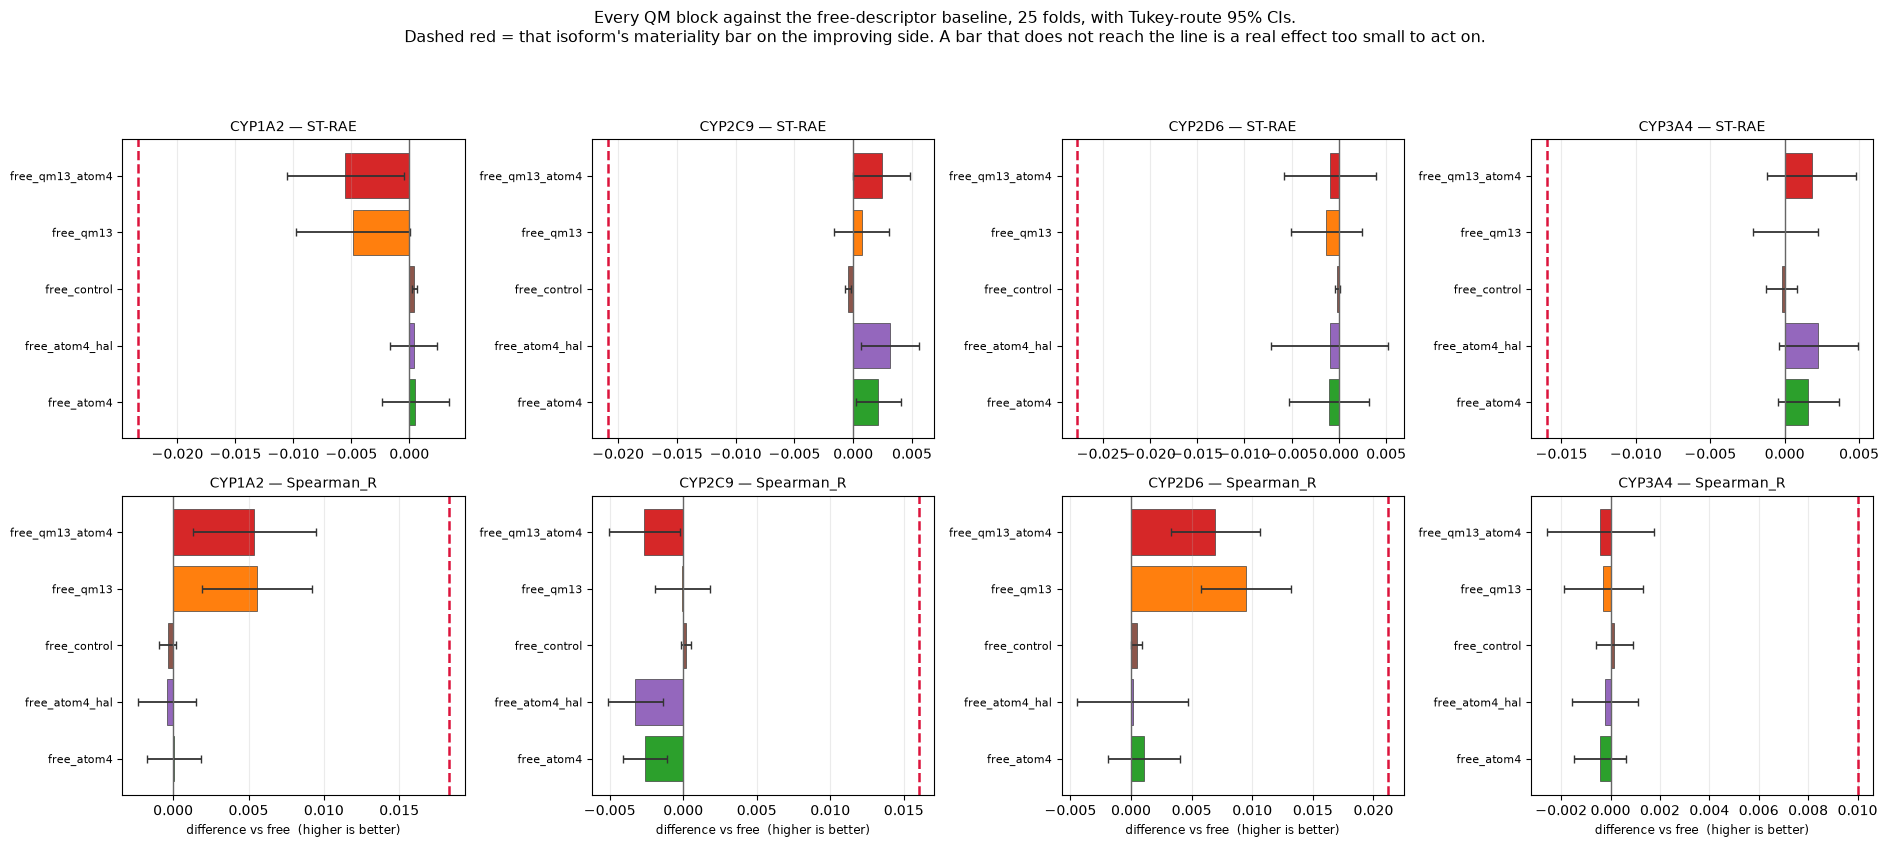

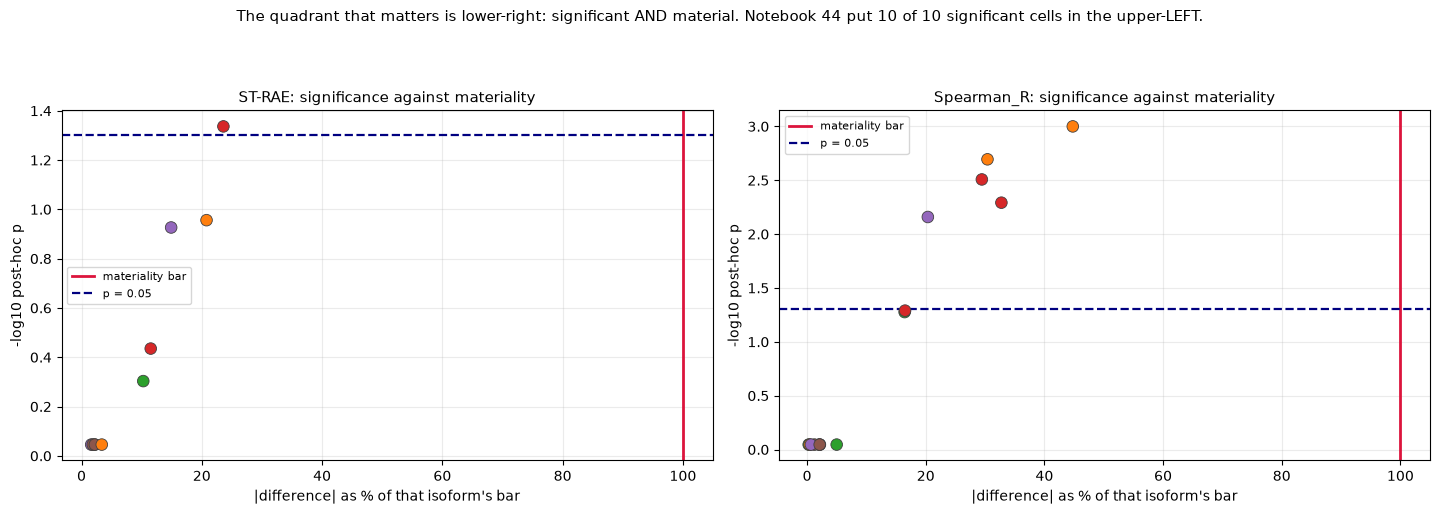

In [12]:
# Part 6 -- figures.
GC = {b: c for b, c in zip(BLOCKS, plt.cm.tab10.colors)}
fig, axes = plt.subplots(2, 4, figsize=(19, 8.6), sharex=False)
for r, m in enumerate(METRICS):
    for c, iso in enumerate(ISO):
        ax = axes[r, c]
        sub = inc[(inc.metric == m) & (inc.isoform == iso)].set_index("arm").reindex(
            [a for a in ARMS if a != BASE_ARM])
        y = np.arange(len(sub))
        ax.barh(y, sub.mean_diff, color=[GC[a.rsplit("__", 1)[0].upper()] for a in sub.index],
                edgecolor="0.25", lw=.5)
        ax.errorbar(sub.mean_diff, y, xerr=[sub.mean_diff - sub.ci_low, sub.ci_high - sub.mean_diff],
                    fmt="none", ecolor="0.2", lw=1.3, capsize=3)
        bar = BARS[m][iso]
        better_sign = -1 if m == "ST-RAE" else 1
        ax.axvline(better_sign * bar, color="crimson", lw=1.8, ls="--")
        ax.axvline(0, color="0.4", lw=1)
        ax.set_yticks(y); ax.set_yticklabels([s.rsplit("__", 1)[0] for s in sub.index], fontsize=8)
        ax.set_title(f"{iso} — {m}", fontsize=10)
        if r == 1: ax.set_xlabel(f"difference vs {BASE_ARM.rsplit('__',1)[0]}"
                                 f"  ({'lower' if m=='ST-RAE' else 'higher'} is better)", fontsize=8.5)
        ax.grid(alpha=.25, axis="x")
fig.suptitle("Every QM block against the free-descriptor baseline, 25 folds, with Tukey-route 95% CIs.\n"
             "Dashed red = that isoform's materiality bar on the improving side. A bar that does not "
             "reach the line is a real effect too small to act on.", fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG / "increment_vs_baseline.png", dpi=170, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
for ax, m in zip(axes, METRICS):
    sub = inc[inc.metric == m]
    ax.scatter(sub.pct_of_bar, -np.log10(sub.p_posthoc.clip(lower=1e-12)),
               c=[GC[a.rsplit("__", 1)[0].upper()] for a in sub.arm], s=70,
               edgecolor="0.25", lw=.6, zorder=3)
    ax.axvline(100, color="crimson", lw=2, label="materiality bar")
    ax.axhline(-np.log10(ALPHA), color="navy", ls="--", lw=1.6, label=f"p = {ALPHA}")
    ax.set(xlabel="|difference| as % of that isoform's bar", ylabel="-log10 post-hoc p")
    ax.set_title(f"{m}: significance against materiality", fontsize=10.5)
    ax.legend(fontsize=8); ax.grid(alpha=.25)
fig.suptitle("The quadrant that matters is lower-right: significant AND material. Notebook 44 put "
             "10 of 10 significant cells in the upper-LEFT.", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(FIG / "significance_vs_materiality.png", dpi=170, bbox_inches="tight")
plt.show()

In [13]:
# Part 7 -- the verdict, derived from the tables.
n_sig = int(inc.significant.sum()); n_mat = int(inc.material.sum())
mat = inc[inc.material]
mat_iso = sorted(mat.isoform.unique())
cyp2d6_only = (set(mat_iso) == {"CYP2D6"})
PASSES = (n_mat > 0) and not cyp2d6_only

print("=" * 100); print(f"{'VERDICT':^100}"); print("=" * 100)
print(f"  methods in the family                       : {len(ARMS)}  (<= 10, so Tukey applies)")
print(f"  post-hoc route(s) fired                     : {routes_used}")
print(f"  omnibus cells clearing alpha={ALPHA_ADJ}            : "
      f"{int(omnibus_table.significant.sum())} of {len(omnibus_table)}")
print(f"  increment cells significant vs baseline     : {n_sig} of {len(inc)}")
print(f"  of those, MATERIAL (>= the bar)             : {n_mat}")
print("-" * 100)
if PASSES:
    print(f"  MATERIAL on: {mat_iso}")
    print(mat[["isoform", "metric", "arm", "mean_diff", "bar", "pct_of_bar"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print("\n  This licenses a full-data retrain as a SEPARATE decision with its own threshold.")
elif n_sig > 0:
    worst = inc.loc[inc[inc.significant].pct_of_bar.idxmax()]
    print(f"  DETECTED, NOT MATERIAL. {n_sig} cells are significant and none reaches its bar;")
    print(f"  the largest is {worst.arm} on {worst.isoform}/{worst.metric} at "
          f"{worst.pct_of_bar:.0f}% of bar.")
    print(f"\n  Pre-declared consequence, frozen before results: a real but immaterial effect does")
    print(f"  NOT justify a submission, and does NOT justify the chemprop atom-feature arm.")
    print(f"  This was the expected outcome -- notebook 44 put 10 of 10 significant cells under")
    print(f"  their bars, the largest at 53%.")
else:
    print(f"  NOT DIFFERENT. No block separates from the free-descriptor baseline.")
print()
if cyp2d6_only:
    print(f"  NOTE: the material set is CYP2D6 alone, which the pre-registration excludes as a")
    print(f"  basis for passing -- notebook 21 established OOF ST-RAE is not a valid ranking")
    print(f"  signal for that isoform, and the real board has contradicted its OOF evidence twice.")
# THE ANSWER FOR THE DESCRIPTORS THIS ARM EXISTED TO TEST, which the baseline table alone does
# not give: against the free block they are confounded with the molecule-level 13 whenever both
# are present, so the contrast that isolates them is Part 5.5's.
q_mol = con[con.question.str.startswith("do the 4 atom descriptors add to the molecule-level")]
q_free = con[con.question.str.startswith("do the 4 atom descriptors add to the free block")]
n_atom_sig = int(q_mol.significant.sum()) + int(q_free.significant.sum())
print(f"  NOTEBOOK 45'S FOUR DESCRIPTORS, isolated -- the question this arm existed to answer:")
print(f"    added to the molecule-level block : {int(q_mol.significant.sum())} of 8 significant, "
      f"{int(q_mol.material.sum())} material")
print(f"    added to the free block alone     : {int(q_free.significant.sum())} of 8 significant, "
      f"{int(q_free.material.sum())} material")
if n_atom_sig == 0:
    print(f"    => NOT DIFFERENT on either contrast. The four descriptors notebook 45 recommended")
    print(f"       do not improve prediction, on 16 of 16 cells, and they are not merely")
    print(f"       immaterial -- they do not reach significance at all.")
    print(f"    => Every significant cell in this arm comes from the MOLECULE-LEVEL block, which")
    print(f"       notebook 44 already tested and found immaterial. Re-asked here it is "
          f"{int(con[con.question.str.startswith('does the molecule-level')].significant.sum())} of 8")
    print(f"       significant and 0 material, reproducing notebook 44's conclusion on a different")
    print(f"       baseline.")
sig = inc[inc.significant]
print(f"\n  DIRECTION, because a significant harm is not a win: of {len(sig)} significant cells vs")
print(f"  the baseline, {int(sig.improves.sum())} improve and {int((~sig.improves).sum())} HARM.")
if (~sig.improves).any():
    for r in sig[~sig.improves].itertuples():
        print(f"    harm: {r.arm} on {r.isoform}/{r.metric}  {r.mean_diff:+.4f}  p {r.p_posthoc:.4f}")
print()
print(f"  CONDITIONING: these p-values are conditional on tier 1's choice of M* = {MSTAR}.")
print(f"  Mitigation, by design: M* was chosen on the BASELINE block alone, on a different")
print(f"  partition, so it cannot have been tuned toward the QM blocks.")
print(f"  NOT A SUBMISSION DECISION: four CV-to-board transfer failures are on record.")
print("=" * 100)
json.dump({"n_methods": len(ARMS), "routes": routes_used, "mstar": MSTAR,
           "n_significant": n_sig, "n_material": n_mat,
           "material_isoforms": mat_iso, "passes": bool(PASSES),
           "verdict": ("MATERIAL" if PASSES else
                       "DETECTED_NOT_MATERIAL" if n_sig else "NOT_DIFFERENT")},
          open(OUT / "verdict.json", "w"), indent=2)

                                              VERDICT                                               
  methods in the family                       : 6  (<= 10, so Tukey applies)
  post-hoc route(s) fired                     : ['tukey']
  omnibus cells clearing alpha=0.025            : 5 of 8
  increment cells significant vs baseline     : 6 of 40
  of those, MATERIAL (>= the bar)             : 0
----------------------------------------------------------------------------------------------------
  DETECTED, NOT MATERIAL. 6 cells are significant and none reaches its bar;
  the largest is free_qm13__ridge on CYP2D6/Spearman_R at 45% of bar.

  Pre-declared consequence, frozen before results: a real but immaterial effect does
  NOT justify a submission, and does NOT justify the chemprop atom-feature arm.
  This was the expected outcome -- notebook 44 put 10 of 10 significant cells under
  their bars, the largest at 53%.

  NOTEBOOK 45'S FOUR DESCRIPTORS, isolated -- the question this arm e

In [14]:
# SCOPE_CHECK_SELF_EXEMPT
# Scope check -- four tests. The already-dirty set and the run timestamp were both recorded at
# the TOP of this run, so TEST 1 answers "did THIS run dirty it" and TEST 2 does not depend on
# inferring a start time from a file mtime (notebooks 42 and 38's respective fixes).
PROTECTED = [
    "data/", "src/calibration.py", "src/chemprop_screen.py", "scripts/44_", "scripts/45_",
    "docs/", "outputs/qm_descriptors/", "outputs/qm_parsed/",
    "outputs/05_cv_comparison/", "outputs/11_caruana_prep/", "outputs/34_butina_5x5/",
    "outputs/35_butina_repeat3/", "outputs/37_butina_5x5_complete/",
    "outputs/44_qm_molecular_block/", "outputs/45_atom_level_screen/",
    "outputs/board_solved_calibration/", "outputs/19_cyp2c9_revert/", "outputs/submissions/",
]
LIVE_SUBMISSION_NOTEBOOKS = ["notebooks/32_deadzone_aid_retrain.ipynb",
                             "notebooks/40_single_object_ensemble.ipynb"]
viol = {1: [], 2: [], 3: [], 4: []}

st = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True).stdout
for ln in st.splitlines():
    if ln.startswith("??"):
        continue
    p = ln[3:].strip()
    if p in ALREADY_DIRTY:
        continue
    if any(p.startswith(q) for q in PROTECTED):
        viol[1].append(p)

for q in PROTECTED:
    root = REPO / q
    cands = [root] if root.is_file() else (root.rglob("*") if root.exists() else [])
    if q.startswith("scripts/4"):
        cands = list(REPO.glob(q + "*"))
    for f in cands:
        if f.is_file() and f.stat().st_mtime > RUN_STARTED_AT.timestamp():
            viol[2].append(str(f.relative_to(REPO)))

for nb in LIVE_SUBMISSION_NOTEBOOKS:
    f = REPO / nb
    if f.exists() and f.stat().st_mtime > RUN_STARTED_AT.timestamp():
        viol[3].append(nb)

import nbformat
me = REPO / "notebooks" / "46_qm_arm.ipynb"
if me.exists():
    for c in nbformat.read(me, as_version=4).cells:
        if c.cell_type == "code" and "SCOPE_CHECK_SELF_EXEMPT" not in c.source:
            for bad in ("gradio_client", "client.predict", "submission_candidate"):
                if bad in c.source:
                    viol[4].append(f"'{bad}' in a code cell")
for f in OUT.rglob("*.csv"):
    if "submission" in f.name:
        viol[4].append(f"submission-shaped file: {f.name}")

NAMES = {1: "tracked-content changes (already-dirty subtracted)", 2: "protected-tree mtime",
         3: "live-submission notebooks never modified", 4: "no submission artefact"}
print("SCOPE CHECK")
for k in sorted(viol):
    print(f"  TEST {k} -- {NAMES[k]:48s} {len(viol[k])} violation(s)" + (f"  {viol[k][:4]}" if viol[k] else ""))
total = sum(len(v) for v in viol.values())
print(f"\n  TOTAL: {total}")
assert total == 0, viol
print("\n  outputs written:")
for f in sorted(OUT.rglob("*")):
    if f.is_file() and f.suffix in (".csv", ".json", ".png", ".txt") and "tier1/predictions" not in str(f) \
       and "/predictions/" not in str(f) and "/scores/" not in str(f) and "/oof_long/" not in str(f):
        print(f"    {f.relative_to(REPO)}")

SCOPE CHECK
  TEST 1 -- tracked-content changes (already-dirty subtracted) 0 violation(s)
  TEST 2 -- protected-tree mtime                             0 violation(s)
  TEST 3 -- live-submission notebooks never modified         0 violation(s)
  TEST 4 -- no submission artefact                           0 violation(s)

  TOTAL: 0

  outputs written:
    outputs/46_qm_arm/cld.csv
    outputs/46_qm_arm/decisive_contrasts.csv
    outputs/46_qm_arm/features/FREE.csv
    outputs/46_qm_arm/features/FREE_ATOM4.csv
    outputs/46_qm_arm/features/FREE_ATOM4_HAL.csv
    outputs/46_qm_arm/features/FREE_CONTROL.csv
    outputs/46_qm_arm/features/FREE_QM13.csv
    outputs/46_qm_arm/features/FREE_QM13_ATOM4.csv
    outputs/46_qm_arm/figures/increment_vs_baseline.png
    outputs/46_qm_arm/figures/significance_vs_materiality.png
    outputs/46_qm_arm/increment_vs_baseline.csv
    outputs/46_qm_arm/levene_homogeneity.csv
    outputs/46_qm_arm/nb44_disclosure.txt
    outputs/46_qm_arm/nb44_pooled_bh_sensi

## What this arm establishes, and what it does not

**The question it answers.** Whether notebook 45's screened QM descriptors improve pIC50 prediction
over the free 2D block they were screened against — tested on 25 folds of the frozen cluster-disjoint
partition, with one variable between the six methods.

**What is new here beyond notebook 44.** Notebook 44 tested the molecule-level block alone and
recorded a negative. The **global-plus-local** combination — the 13 molecule-level columns together
with the 4 atom-level descriptors, which is the shape qcMol and QMex use — had never been tested in
this project, and notebook 45's Part 7 established it contains no near-duplicate pair (0 of 116
pairwise correlations above 0.80; `hirshfeld_C_min` against `hirshfeld_min` at −0.01). So this is not
a re-run of notebook 44's question.

**What it cannot establish.**

1. **Board performance.** Four CV-to-board transfer failures are on record, including one
   (notebook 29 → NB30) that was fully 5×5-confirmed and still reversed. A CV result here is
   evidence about information content, not a forecast.
2. **That an immaterial effect is zero.** The bars measure what a 25-fold paired comparison on this
   partition can resolve. An effect below the bar is real and too small to act on — not absent.
3. **Anything about CYP2D6 on its own.** Notebook 21 established OOF ST-RAE is not a valid ranking
   signal for it, and the real board has contradicted its OOF evidence twice.
4. **Whether a higher-resolution use of the same data would work.** Collapsing 252,237 atom rows to
   four columns is a lossy summary. Feeding the per-atom values into the graph directly is a
   different design, scoped but deliberately not run — notebook 44's `plain_qm` (chemprop with the
   18 molecule-level QM columns) was null on all four isoforms, and notebook 18's charge descriptor
   tied, so its prior is poor and its cost is 4–5 h plus an atom-ordering hazard that would need a
   hard assertion to be safe.

**Standing caveat on the route.** The parametric default was chosen partly because its justification
is in the main text we hold; the BH exception and the nonparametric workflow are cited to a
Supporting Information that is not in this environment. If a cell routed nonparametric above, its
confidence interval is a paired-*t* estimate reported beside the test, not produced by it.